# EN3160 Assignment 1 - Intensity Transformations and Neighborhood Filtering
**D. P. Heshan Ranasinghe | Index: [ADD INDEX] | [GitHub](https://github.com/DPHeshanRanasinghe)**

In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

IMAGE_DIR = Path("images")
plt.rcParams.update({"font.size": 8, "figure.dpi": 130})

## 1. Piecewise intensity transformation
The vertical lines in Fig. 1a are jumps in the transformation, so the input values 50 and 150 appear twice. I used linear interpolation only between points with different input values.

In [2]:
def intensity_transform(im, breakpoints):
    breakpoints = np.asarray(breakpoints, dtype=float)
    transformed = np.zeros(im.shape, dtype=float)

    for (x1, y1), (x2, y2) in zip(breakpoints[:-1], breakpoints[1:]):
        if x1 == x2:                 # vertical jump
            continue
        mask = (im >= x1) & (im < x2)
        transformed[mask] = y1 + (im[mask] - x1) * (y2 - y1) / (x2 - x1)

    transformed[im == breakpoints[-1, 0]] = breakpoints[-1, 1]
    return np.clip(np.rint(transformed), 0, 255).astype(np.uint8)

# Points read directly from Fig. 1a (repeated x-values draw the jumps)
figure_breakpoints = np.array([
    [0, 0], [50, 50], [50, 100], [150, 255], [150, 150], [255, 255]
])

# Five points printed in the question
printed_breakpoints = np.array([
    [0, 0], [50, 50], [100, 150], [150, 255], [255, 255]
])

# Final points selected after trying less aggressive curves
chosen_breakpoints = np.array([
    [0, 0], [35, 50], [85, 120], [130, 175], [190, 230], [255, 255]
])

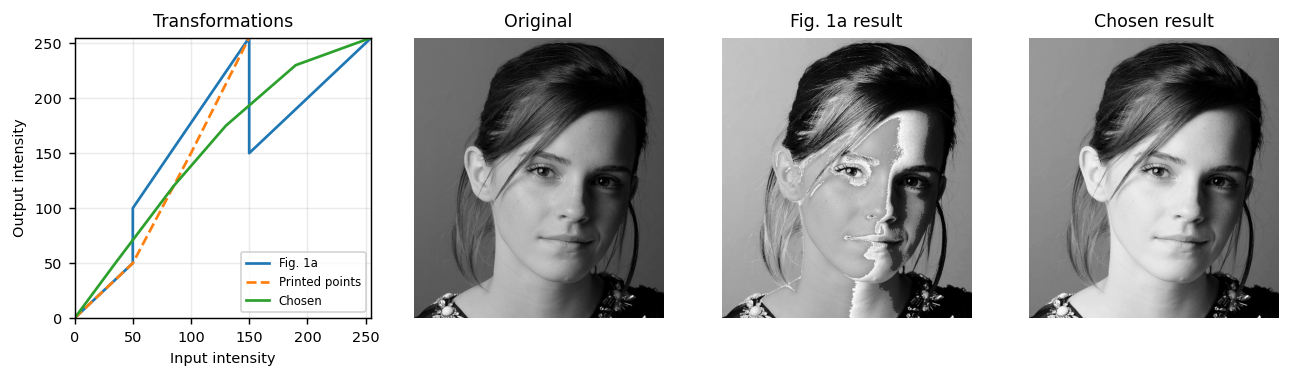

Chosen result - mean: 92.3 -> 122.2, standard deviation: 56.1 -> 67.8


In [3]:
image = cv2.imread(str(IMAGE_DIR / "q01_portrait_intensity_transform.jpeg"), cv2.IMREAD_GRAYSCALE)
if image is None:
    raise FileNotFoundError("Question 1 image was not found")

figure_result = intensity_transform(image, figure_breakpoints)
chosen_result = intensity_transform(image, chosen_breakpoints)

fig, axes = plt.subplots(1, 4, figsize=(10, 2.8), constrained_layout=True)
axes[0].plot(figure_breakpoints[:, 0], figure_breakpoints[:, 1], label="Fig. 1a")
axes[0].plot(printed_breakpoints[:, 0], printed_breakpoints[:, 1], "--", label="Printed points")
axes[0].plot(chosen_breakpoints[:, 0], chosen_breakpoints[:, 1], label="Chosen")
axes[0].set(xlabel="Input intensity", ylabel="Output intensity", xlim=(0, 255), ylim=(0, 255), title="Transformations")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=6.5)

for ax, result, title in zip(axes[1:], [image, figure_result, chosen_result], ["Original", "Fig. 1a result", "Chosen result"]):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()
print(f"Chosen result - mean: {image.mean():.1f} -> {chosen_result.mean():.1f}, standard deviation: {image.std():.1f} -> {chosen_result.std():.1f}")

**Interpretation.** The Fig. 1a transformation brightens intensities from 50 to 149 strongly, but the jumps at 50 and 150 produce obvious bright bands on the face. I therefore tried smoother breakpoint sets and selected the final curve shown above. It increased the mean from **92.3 to 122.2** and the standard deviation from **56.1 to 67.8**, making the face and hair clearer without the harsh bands produced by Fig. 1a.